# 06 · Evaluation on the test set (used once)

**Goal:** measure how well the trained models recognise defects on 270 images they have never seen, with extra attention to cracks (the crazing class).

**Inputs:** the test split from notebook 02, the saved models from notebooks 04 and 05.

**Outputs:**
- `outputs/results/test_metrics.csv`, `classification_report_<model>.txt`, `test_predictions.csv`, `evaluation_summary.json`
- figures `outputs/figures/eval_01` to `eval_04`

**The rule:** the test set is opened here and only here, once, after all models are trained and the finalists were chosen on the validation set (notebook 05). Nothing is changed after seeing these numbers. All three models are scored in the same single pass so the table is complete, but the finalists are the ones we report as our result.

## Setup

In [1]:
import json
import time
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_recall_fscore_support
from tensorflow import keras

SEED = 42
ON_KAGGLE = Path("/kaggle/input").exists()

if ON_KAGGLE:
    PROJECT = Path("/kaggle/working")
    INPUT = Path("/kaggle/input")
    DATA_ROOT = next(INPUT.rglob("NEU-DET")).parent
    SPLIT_DIR = next(INPUT.rglob("test.csv")).parent
    MODEL_FILES = {p.stem: p for p in INPUT.rglob("*.keras")}
    VAL_RESULTS = next(INPUT.rglob("val_results.csv"))
else:
    PROJECT = Path.cwd().parent
    DATA_ROOT = PROJECT / "data" / "raw"
    SPLIT_DIR = PROJECT / "data" / "splits"
    MODEL_FILES = {p.stem: p for p in (PROJECT / "outputs" / "models").glob("*.keras")}
    VAL_RESULTS = PROJECT / "outputs" / "results" / "val_results.csv"

FIG_DIR = PROJECT / "outputs" / "figures"
RES_DIR = PROJECT / "outputs" / "results"
for folder in (FIG_DIR, RES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

CLASSES = ["crazing", "inclusion", "patches", "pitted_surface", "rolled-in_scale", "scratches"]
CLASS_NAMES = ["Crazing", "Inclusion", "Patches", "Pitted surface", "Rolled-in scale", "Scratches"]
MODELS = ["m1_baseline", "m2_improved", "m3_mobilenetv2"]
FINALISTS = ["m3_mobilenetv2", "m1_baseline"]  # chosen on the validation set in notebook 05

test_df = pd.read_csv(SPLIT_DIR / "test.csv")
y_true = np.array([CLASSES.index(c) for c in test_df["label"]])
print("test images:", len(test_df), "| models found:", sorted(MODEL_FILES))
pd.read_csv(VAL_RESULTS)[["model", "val_accuracy", "val_loss", "params"]]

test images: 270 | models found: ['m1_baseline', 'm2_improved', 'm3_mobilenetv2']


,model,val_accuracy,val_loss,params
0,m1_baseline,0.9704,0.1056,109958
1,m2_improved,0.9593,0.1310,110630
2,m3_mobilenetv2,0.9704,0.0832,2265670


## Load the test images and the models

Same loading as in training: grayscale, 200 × 200 scaled to 0..1 for our own CNNs, and 224 × 224 × 3 through `preprocess_input` for MobileNetV2.

In [2]:
def load_images(size, three_channels):
    images = []
    for rel in test_df["filepath"]:
        img = tf.io.decode_jpeg(tf.io.read_file(str(DATA_ROOT / rel)), channels=1)
        img = tf.image.resize(img, (size, size))
        if three_channels:
            img = keras.applications.mobilenet_v2.preprocess_input(tf.image.grayscale_to_rgb(img))
        else:
            img = img / 255.0
        images.append(img.numpy())
    return np.stack(images)


inputs = {
    "m1_baseline": load_images(200, False),
    "m2_improved": None,
    "m3_mobilenetv2": load_images(224, True),
}
inputs["m2_improved"] = inputs["m1_baseline"]
models = {name: keras.models.load_model(MODEL_FILES[name]) for name in MODELS}

test_opened_at = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M:%S UTC")
print("test set opened at", test_opened_at)

I0000 00:00:1792298322.906144      20 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792298322.909823      20 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


test set opened at 2026-10-18 04:38:53 UTC


## Predictions and metrics

- **Accuracy:** share of test images classified correctly.
- **Macro precision / recall / F1:** computed per class and then averaged, so every class counts the same.
- **Crack metrics:** crazing against the other five classes. Recall is the one that matters most: a missed crack ships to the customer.

In [3]:
rows, probs = [], {}
predictions = test_df[["filepath", "label"]].copy()
for name in MODELS:
    p = models[name].predict(inputs[name], batch_size=64, verbose=0)
    probs[name] = p
    y_pred = p.argmax(axis=1)
    predictions[f"pred_{name}"] = [CLASSES[i] for i in y_pred]
    predictions[f"conf_{name}"] = p.max(axis=1).round(4)

    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    crack_true, crack_pred = y_true == 0, y_pred == 0
    c_prec, c_rec, c_f1, _ = precision_recall_fscore_support(crack_true, crack_pred, average="binary", zero_division=0)
    rows.append({
        "model": name,
        "finalist": name in FINALISTS,
        "accuracy": round(accuracy_score(y_true, y_pred), 4),
        "macro_precision": round(prec, 4),
        "macro_recall": round(rec, 4),
        "macro_f1": round(f1, 4),
        "crack_precision": round(c_prec, 4),
        "crack_recall": round(c_rec, 4),
        "crack_f1": round(c_f1, 4),
        "errors": int((y_pred != y_true).sum()),
    })
    report = classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0)
    (RES_DIR / f"classification_report_{name}.txt").write_text(report)
    print(name, "\n", report)

predictions.to_csv(RES_DIR / "test_predictions.csv", index=False)

I0000 00:00:1792298336.432605      67 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


m1_baseline 
                  precision    recall  f1-score   support

        Crazing     0.9783    1.0000    0.9890        45
      Inclusion     0.8182    1.0000    0.9000        45
        Patches     1.0000    0.9778    0.9888        45
 Pitted surface     0.9722    0.7778    0.8642        45
Rolled-in scale     0.9783    1.0000    0.9890        45
      Scratches     0.9302    0.8889    0.9091        45

       accuracy                         0.9407       270
      macro avg     0.9462    0.9407    0.9400       270
   weighted avg     0.9462    0.9407    0.9400       270

m2_improved 
                  precision    recall  f1-score   support

        Crazing     0.9375    1.0000    0.9677        45
      Inclusion     0.9333    0.9333    0.9333        45
        Patches     1.0000    1.0000    1.0000        45
 Pitted surface     0.9302    0.8889    0.9091        45
Rolled-in scale     1.0000    1.0000    1.0000        45
      Scratches     1.0000    0.9778    0.9888        45

## Speed and size

A steel strip moves fast, so the time per image matters. We time each model on the **CPU**, one image at a time, because a small computer next to the line may have no GPU. The first 10 calls are a warm-up and are not counted.

In [4]:
def cpu_ms_per_image(model, images, n=100):
    with tf.device("/CPU:0"):
        for i in range(10):
            model(images[i:i + 1], training=False)
        start = time.perf_counter()
        for i in range(n):
            model(images[i:i + 1], training=False)
    return (time.perf_counter() - start) / n * 1000


for row in rows:
    name = row["model"]
    row["cpu_ms_per_image"] = round(cpu_ms_per_image(models[name], inputs[name]), 2)
    row["params"] = int(models[name].count_params())
    row["model_size_mb"] = round(MODEL_FILES[name].stat().st_size / 1e6, 2)

test_metrics = pd.DataFrame(rows)
test_metrics.to_csv(RES_DIR / "test_metrics.csv", index=False)
test_metrics

,model,finalist,accuracy,macro_precision,macro_recall,macro_f1,crack_precision,crack_recall,crack_f1,errors,cpu_ms_per_image,params,model_size_mb
0,m1_baseline,True,0.9407,0.9462,0.9407,0.9400,0.9783,1.0,0.9890,16,21.57,109958,1.38
1,m2_improved,False,0.9667,0.9668,0.9667,0.9665,0.9375,1.0,0.9677,9,29.31,110630,1.41
2,m3_mobilenetv2,True,0.9852,0.9860,0.9852,0.9852,1.0000,1.0,1.0000,4,223.96,2265670,24.46


## Confusion matrices of the finalists

Each row is the true class and each column the predicted class. The diagonal holds the correct answers; anything off the diagonal is a mix-up. The right panel shows each row as a share of that class, which makes weak classes easy to spot.

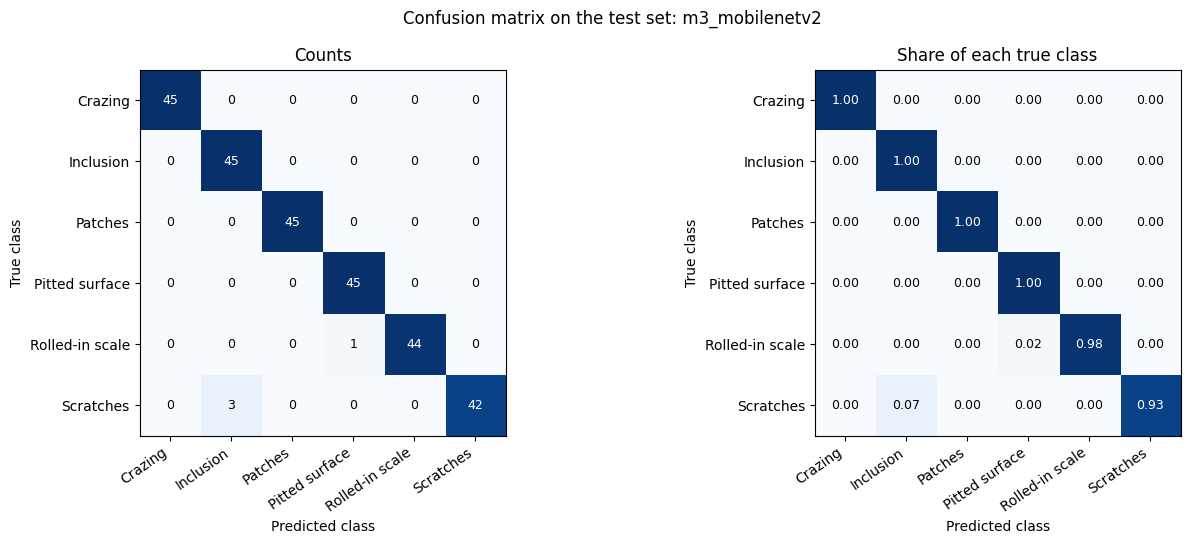

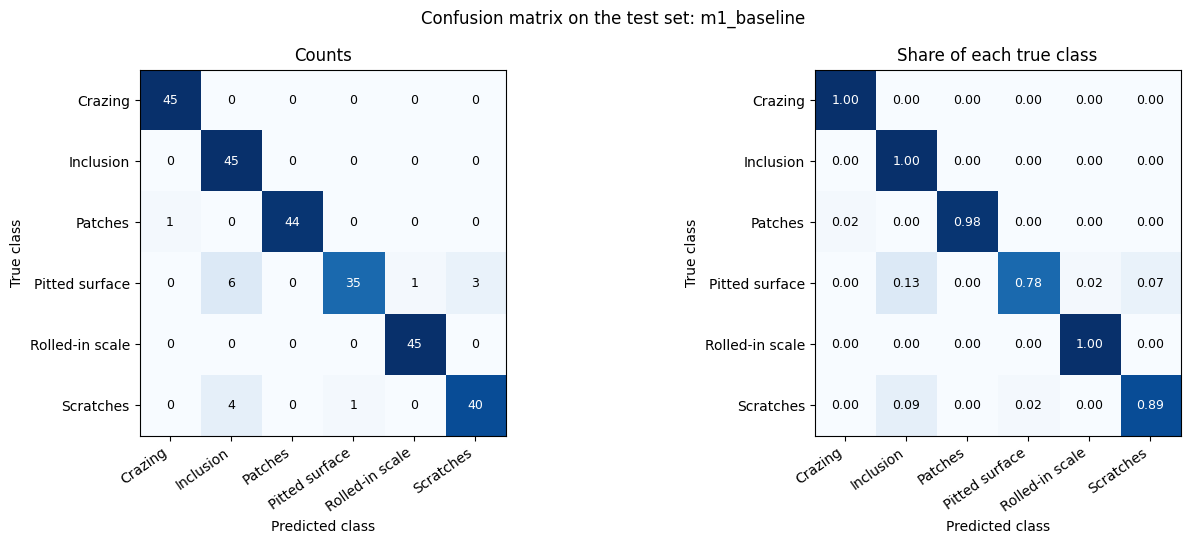

In [5]:
for k, name in enumerate(FINALISTS, start=1):
    cm = confusion_matrix(y_true, probs[name].argmax(axis=1), labels=range(len(CLASSES)))
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
    for ax, matrix, title, fmt in ((axes[0], cm, "Counts", "d"), (axes[1], cm_norm, "Share of each true class", ".2f")):
        ax.imshow(matrix, cmap="Blues")
        ax.set_xticks(range(len(CLASSES)), CLASS_NAMES, rotation=35, ha="right")
        ax.set_yticks(range(len(CLASSES)), CLASS_NAMES)
        ax.set_xlabel("Predicted class")
        ax.set_ylabel("True class")
        ax.set_title(title)
        for i in range(len(CLASSES)):
            for j in range(len(CLASSES)):
                value = matrix[i, j]
                ax.text(j, i, format(value, fmt), ha="center", va="center",
                        color="white" if value > matrix.max() * 0.6 else "black", fontsize=9)
    fig.suptitle(f"Confusion matrix on the test set: {name}", fontsize=12)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"eval_0{k}_confusion_{name}.png", dpi=150)
    plt.show()

## The images the finalists got wrong

Looking at the actual mistakes tells us more than any number: are they ambiguous images, or a gap in the model?

test images missed by at least one finalist: 19


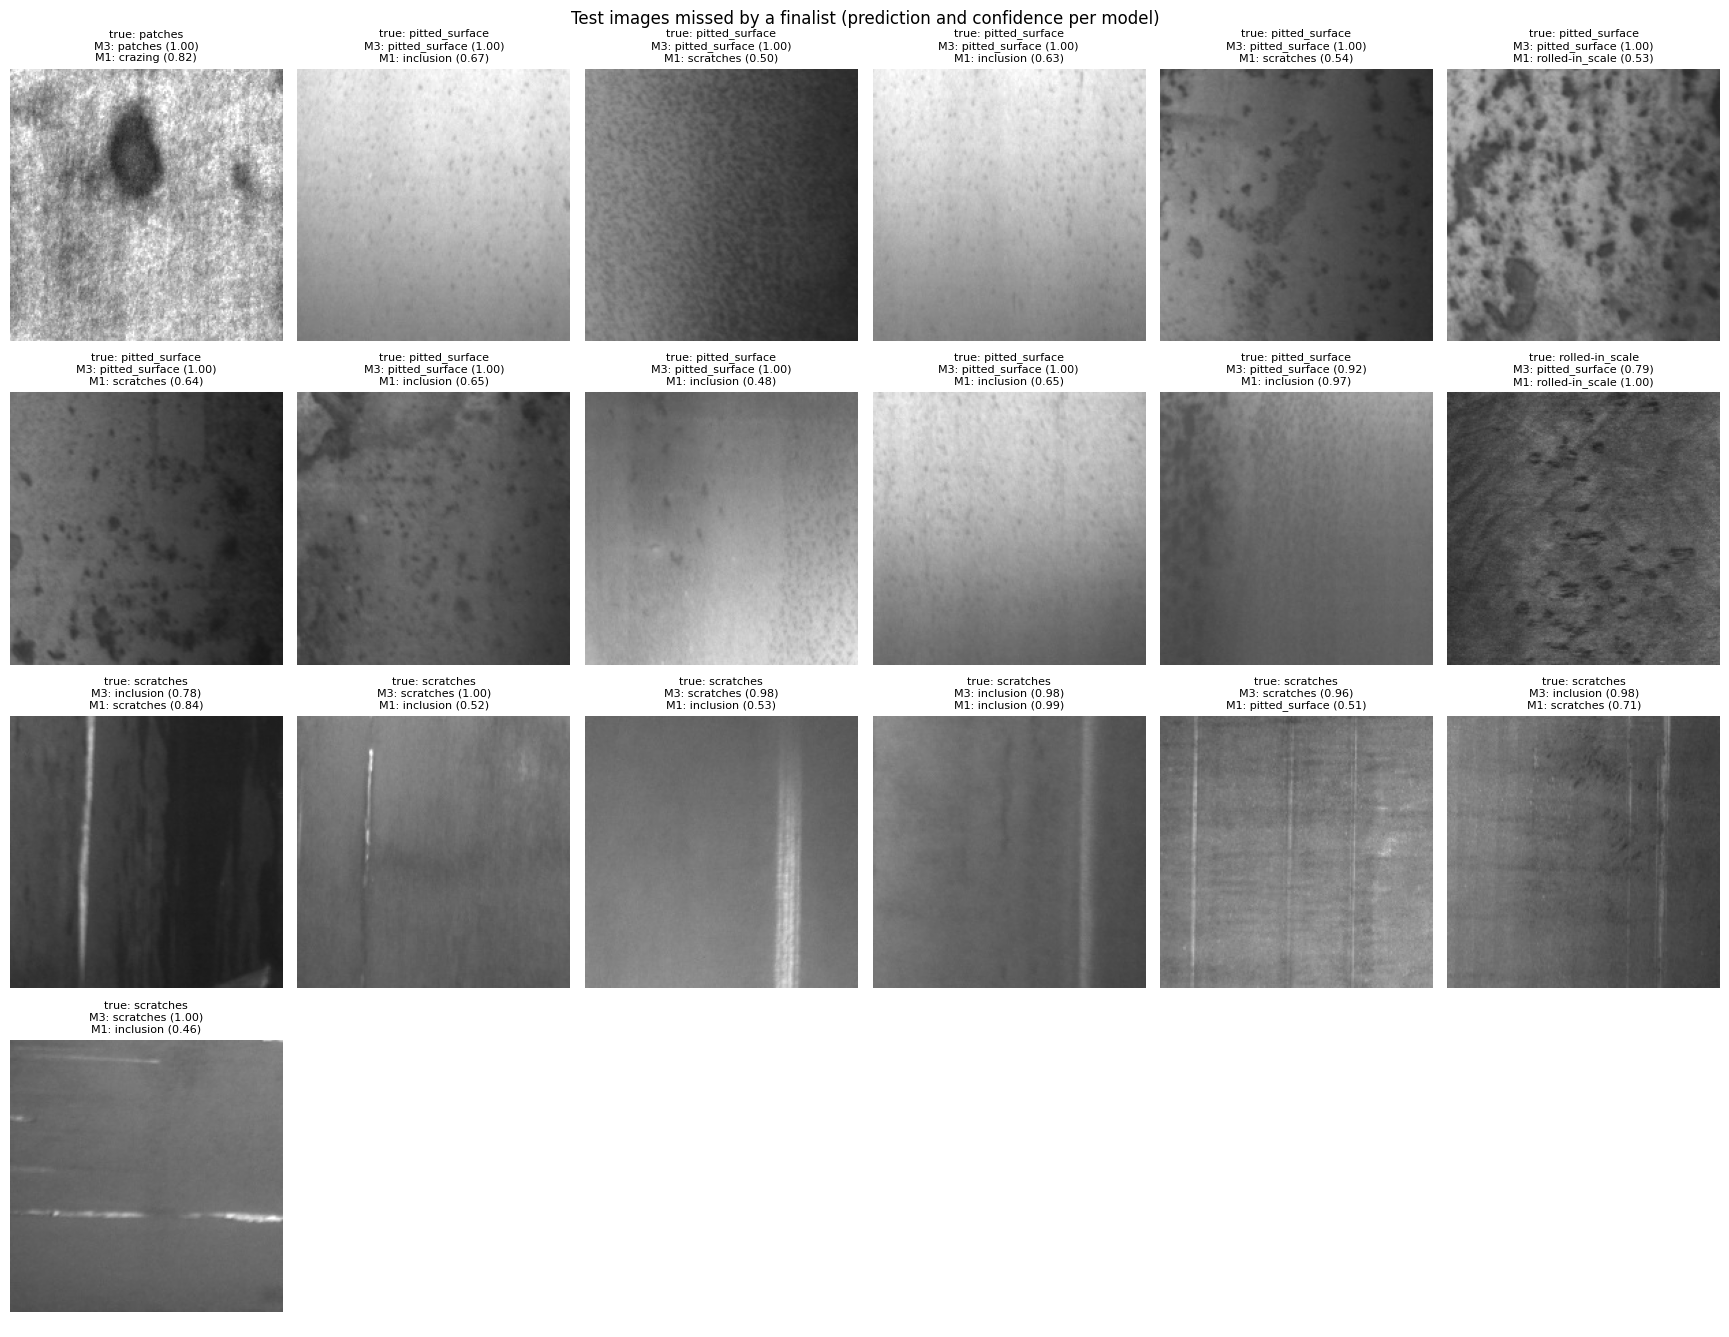

In [6]:
wrong = predictions[np.any([predictions[f"pred_{n}"] != predictions["label"] for n in FINALISTS], axis=0)]
print("test images missed by at least one finalist:", len(wrong))
if len(wrong):
    cols = min(len(wrong), 6)
    rows_n = int(np.ceil(len(wrong) / cols))
    fig, axes = plt.subplots(rows_n, cols, figsize=(2.9 * cols, 3.4 * rows_n), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (_, r) in zip(axes.ravel(), wrong.iterrows()):
        with Image.open(DATA_ROOT / r["filepath"]) as im:
            ax.imshow(im.convert("L"), cmap="gray", vmin=0, vmax=255)
        lines = [f"true: {r['label']}"] + [f"{n[:2].upper()}: {r[f'pred_{n}']} ({r[f'conf_{n}']:.2f})" for n in FINALISTS]
        ax.set_title("\n".join(lines), fontsize=8)
    fig.suptitle("Test images missed by a finalist (prediction and confidence per model)", fontsize=12)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "eval_03_misclassified.png", dpi=150)
    plt.show()

## All models side by side

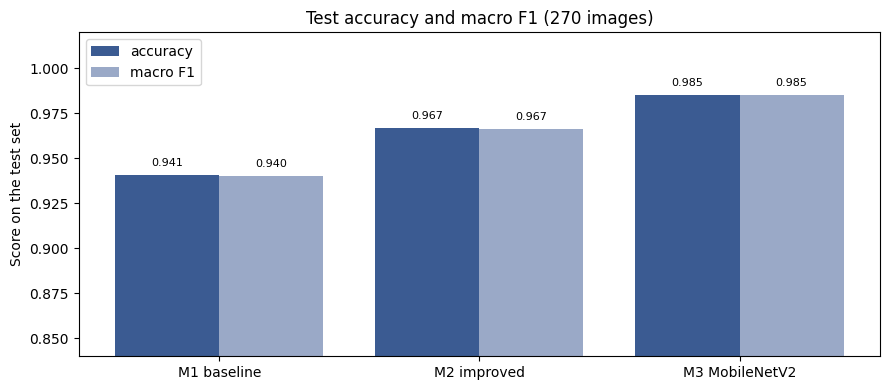

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(test_metrics))
ax.bar(x - 0.2, test_metrics["accuracy"], 0.4, label="accuracy", color="#3b5b92")
ax.bar(x + 0.2, test_metrics["macro_f1"], 0.4, label="macro F1", color="#9aa9c7")
for i, (a, f) in enumerate(zip(test_metrics["accuracy"], test_metrics["macro_f1"])):
    ax.text(i - 0.2, a + 0.005, f"{a:.3f}", ha="center", fontsize=8)
    ax.text(i + 0.2, f + 0.005, f"{f:.3f}", ha="center", fontsize=8)
ax.set_xticks(x, ["M1 baseline", "M2 improved", "M3 MobileNetV2"])
ax.set_ylim(max(0.0, test_metrics[["accuracy", "macro_f1"]].min().min() - 0.1), 1.02)
ax.set_ylabel("Score on the test set")
ax.set_title("Test accuracy and macro F1 (270 images)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "eval_04_test_comparison.png", dpi=150)
plt.show()

## Save the summary

In [8]:
summary = {
    "test_opened_at": test_opened_at,
    "test_images": int(len(test_df)),
    "finalists": FINALISTS,
    "metrics": test_metrics.to_dict(orient="records"),
}
(RES_DIR / "evaluation_summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

{
  "test_opened_at": "2026-10-18 04:38:53 UTC",
  "test_images": 270,
  "finalists": [
    "m3_mobilenetv2",
    "m1_baseline"
  ],
  "metrics": [
    {
      "model": "m1_baseline",
      "finalist": true,
      "accuracy": 0.9407,
      "macro_precision": 0.9462,
      "macro_recall": 0.9407,
      "macro_f1": 0.94,
      "crack_precision": 0.9783,
      "crack_recall": 1.0,
      "crack_f1": 0.989,
      "errors": 16,
      "cpu_ms_per_image": 21.57,
      "params": 109958,
      "model_size_mb": 1.38
    },
    {
      "model": "m2_improved",
      "finalist": false,
      "accuracy": 0.9667,
      "macro_precision": 0.9668,
      "macro_recall": 0.9667,
      "macro_f1": 0.9665,
      "crack_precision": 0.9375,
      "crack_recall": 1.0,
      "crack_f1": 0.9677,
      "errors": 9,
      "cpu_ms_per_image": 29.31,
      "params": 110630,
      "model_size_mb": 1.41
    },
    {
      "model": "m3_mobilenetv2",
      "finalist": true,
      "accuracy": 0.9852,
      "macro_precisi

## What we found

- **M3 (MobileNetV2) is our final model:** 98.52 % test accuracy and macro F1 0.985, with 4 mistakes in 270 images.
- **Cracks:** all 45 crazing test images were found by every model (crack recall 100 %). M3 raised no false crack alarm (crack precision 100 %); M1 called one patches image crazing.
- **M1 dropped from 97.04 % on validation to 94.07 % on test.** 10 of its 16 mistakes are pitted-surface images, called inclusion (6), scratches (3) or rolled-in scale (1), and 9 of those 10 with a confidence below 0.7.
- **M2, which was not a finalist, scored 96.67 %, 7 images better than M1**, the opposite of the validation ranking. With 270 images in each set, validation could not separate two models this close. We keep the finalists we chose before opening the test, and report this openly.
- **M3's four mistakes:** three faint scratches called inclusion and one rolled-in scale image called pitted surface. A thin line running along the rolling direction looks much like a long inclusion.
- **Speed and size:** on Kaggle's CPU, one image takes 21.6 ms with M1 and 224 ms with M3, about 10 times slower, and M3's file is 18 times larger. M3 is the more accurate choice; M1 suits a very small computer next to the line.